In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from pathlib import Path

project_path = Path.home() / "Desktop" / "OIBSIP" / "DataAnalytics-L1-EDARetailSales"

print("Project folder exists:", project_path.exists())
print("\nFiles available:")

for file in project_path.iterdir():
    print(file.name)


Project folder exists: True

Files available:
retail_sales_dataset.csv
.venv
.ipynb_checkpoints
Retail_Sales_EDA.ipynb


In [3]:

from pathlib import Path

project_path = Path.home() / "Desktop" / "OIBSIP" / "DataAnalytics-L1-EDARetailSales"

csv_files = list(project_path.glob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file.name)


CSV files found: 1
retail_sales_dataset.csv


In [4]:

import pandas as pd
from pathlib import Path

project_path = Path.home() / "Desktop" / "OIBSIP" / "DataAnalytics-L1-EDARetailSales"
file_path = project_path / "retail_sales_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())


Dataset loaded successfully!
Dataset Shape: (1000, 9)

First 5 Rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:

print("Column Names:")
print(df.columns.tolist())

print("\nData Types and Non-Null Counts:")
df.info()


Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB


In [6]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows: 0


In [7]:

print("Numerical Summary:")
display(df.describe())

print("\nMean:")
display(df.mean(numeric_only=True))

print("\nMedian:")
display(df.median(numeric_only=True))

print("\nMode:")
display(df.mode().iloc[0])

print("\nStandard Deviation:")
display(df.std(numeric_only=True))


Numerical Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



Mean:


Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64


Median:


Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64


Mode:


Transaction ID               1
Date                2023-05-16
Customer ID            CUST001
Gender                  Female
Age                       43.0
Product Category      Clothing
Quantity                   4.0
Price per Unit            50.0
Total Amount              50.0
Name: 0, dtype: object


Standard Deviation:


Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

In [8]:

print("Total Transactions:", df["Transaction ID"].nunique())
print("Total Sales Revenue:", df["Total Amount"].sum())
print("Average Transaction Amount:", df["Total Amount"].mean())
print("Median Transaction Amount:", df["Total Amount"].median())
print("Total Quantity Sold:", df["Quantity"].sum())
print("Unique Customers:", df["Customer ID"].nunique())


Total Transactions: 1000
Total Sales Revenue: 456000
Average Transaction Amount: 456.0
Median Transaction Amount: 135.0
Total Quantity Sold: 2514
Unique Customers: 1000


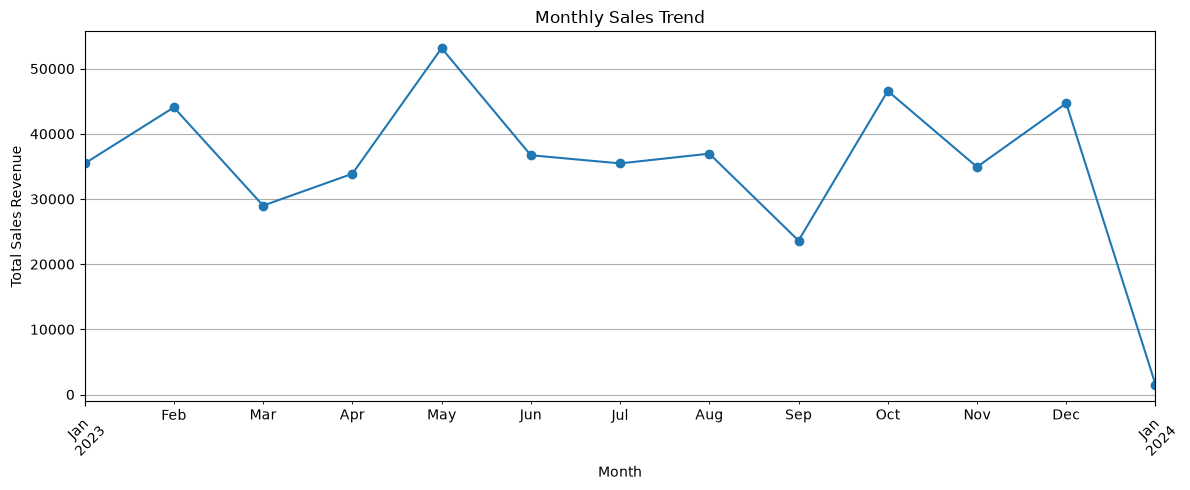

Monthly Sales:


Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

In [9]:

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Extract month and calculate monthly sales
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Total Amount"].sum()

# Plot monthly sales trend
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print("Monthly Sales:")
display(monthly_sales)


In [10]:

best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()

print("Best Sales Month:", best_month)
print("Highest Monthly Sales:", best_month_sales)

print("\nLowest Sales Month:", monthly_sales.idxmin())
print("Lowest Monthly Sales:", monthly_sales.min())


Best Sales Month: 2023-05
Highest Monthly Sales: 53150

Lowest Sales Month: 2024-01
Lowest Monthly Sales: 1530


Sales Revenue by Product Category:


Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

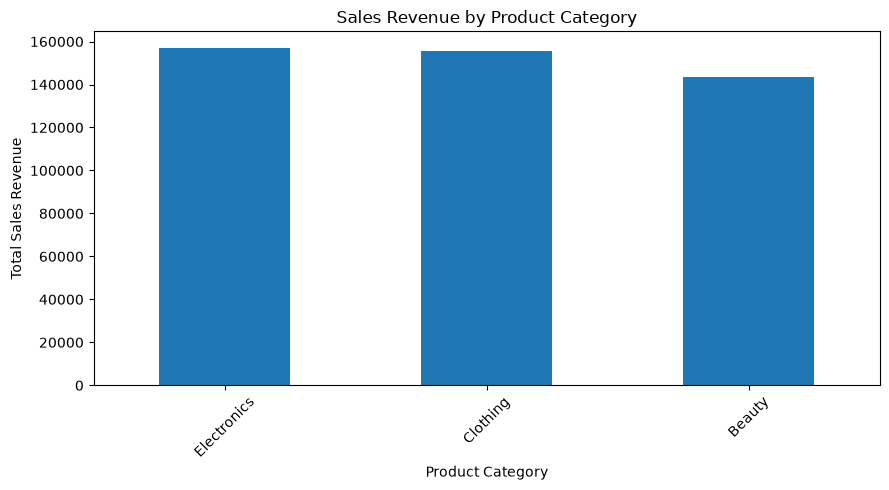

In [11]:

category_sales = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales Revenue by Product Category:")
display(category_sales)

# Bar chart
plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar")

plt.title("Sales Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:

best_category = category_sales.idxmax()
best_category_sales = category_sales.max()

print("Top Performing Category:", best_category)
print("Category Sales Revenue:", best_category_sales)

print("\nLowest Performing Category:", category_sales.idxmin())
print("Lowest Category Sales:", category_sales.min())


Top Performing Category: Electronics
Category Sales Revenue: 156905

Lowest Performing Category: Beauty
Lowest Category Sales: 143515


Gender-wise Analysis:


,Total_Customers,Total_Transactions,Total_Sales,Average_Sales
Gender,,,,
Female,510,510,232840,456.549020
Male,490,490,223160,455.428571


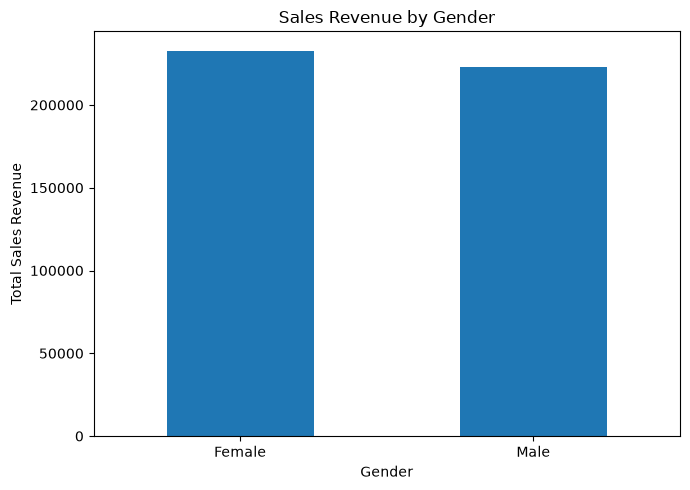

In [13]:

gender_analysis = df.groupby("Gender").agg(
    Total_Customers=("Customer ID", "nunique"),
    Total_Transactions=("Transaction ID", "count"),
    Total_Sales=("Total Amount", "sum"),
    Average_Sales=("Total Amount", "mean")
)

print("Gender-wise Analysis:")
display(gender_analysis)

# Gender-wise revenue chart
gender_sales = df.groupby("Gender")["Total Amount"].sum()

plt.figure(figsize=(7, 5))
gender_sales.plot(kind="bar")

plt.title("Sales Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Age Group Analysis:


,Customers,Transactions,Total_Sales
Age Group,,,
Under 18,21,21,11215
18-25,148,148,73335
26-35,205,205,98480
36-45,202,202,91870
46-55,229,229,100690
56+,195,195,80410


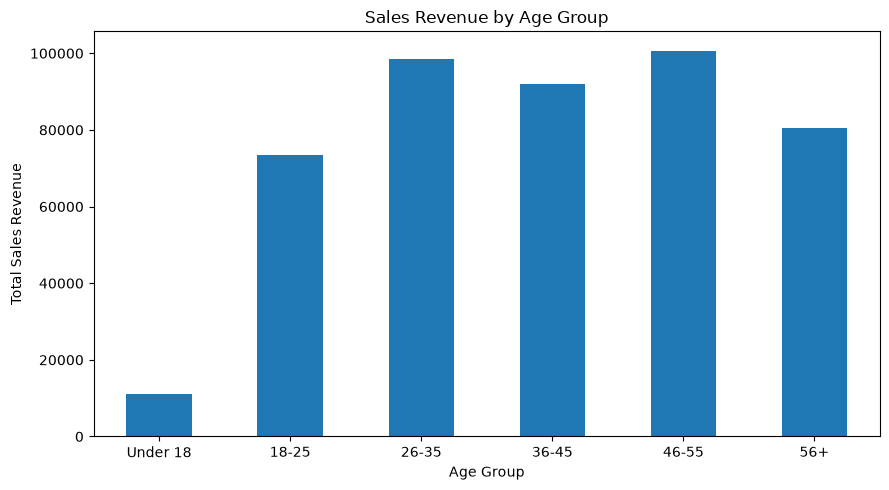

In [14]:

# Create age groups
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=["Under 18", "18-25", "26-35", "36-45", "46-55", "56+"],
    include_lowest=True
)

age_analysis = df.groupby("Age Group", observed=False).agg(
    Customers=("Customer ID", "nunique"),
    Transactions=("Transaction ID", "count"),
    Total_Sales=("Total Amount", "sum")
)

print("Age Group Analysis:")
display(age_analysis)

# Sales by age group
plt.figure(figsize=(9, 5))
age_analysis["Total_Sales"].plot(kind="bar")

plt.title("Sales Revenue by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Top 10 Transactions by Sales Amount:


,Transaction ID,Date,Customer ID,Product Category,Quantity,Total Amount
14,15,2023-01-16,CUST015,Electronics,4,2000
64,65,2023-12-05,CUST065,Electronics,4,2000
71,72,2023-05-23,CUST072,Electronics,4,2000
73,74,2023-11-22,CUST074,Beauty,4,2000
88,89,2023-10-01,CUST089,Electronics,4,2000
92,93,2023-07-14,CUST093,Beauty,4,2000
108,109,2023-10-18,CUST109,Electronics,4,2000
117,118,2023-05-16,CUST118,Electronics,4,2000
123,124,2023-10-27,CUST124,Clothing,4,2000
138,139,2023-12-15,CUST139,Beauty,4,2000


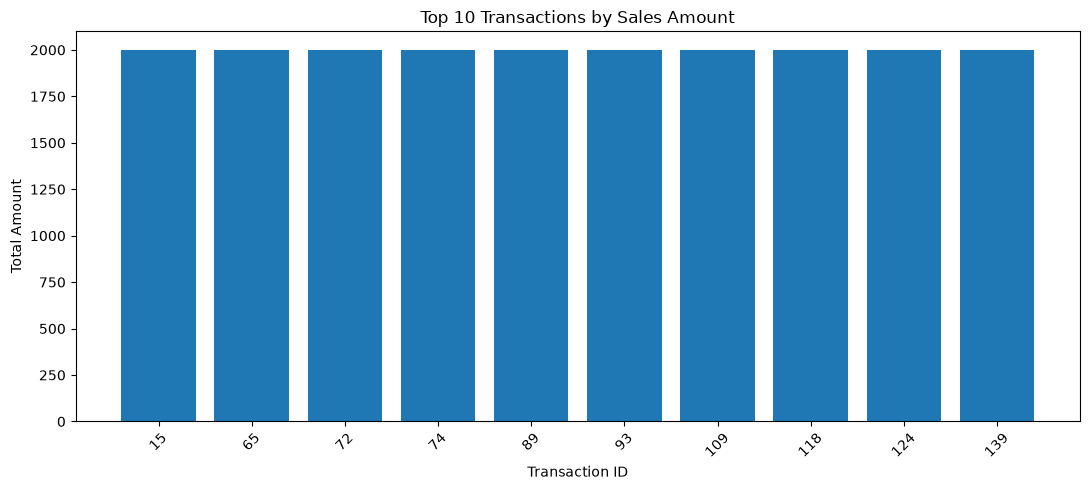

In [15]:

top_10_transactions = df.nlargest(10, "Total Amount")[
    ["Transaction ID", "Date", "Customer ID",
     "Product Category", "Quantity", "Total Amount"]
]

print("Top 10 Transactions by Sales Amount:")
display(top_10_transactions)

plt.figure(figsize=(11, 5))
plt.bar(
    top_10_transactions["Transaction ID"].astype(str),
    top_10_transactions["Total Amount"]
)

plt.title("Top 10 Transactions by Sales Amount")
plt.xlabel("Transaction ID")
plt.ylabel("Total Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


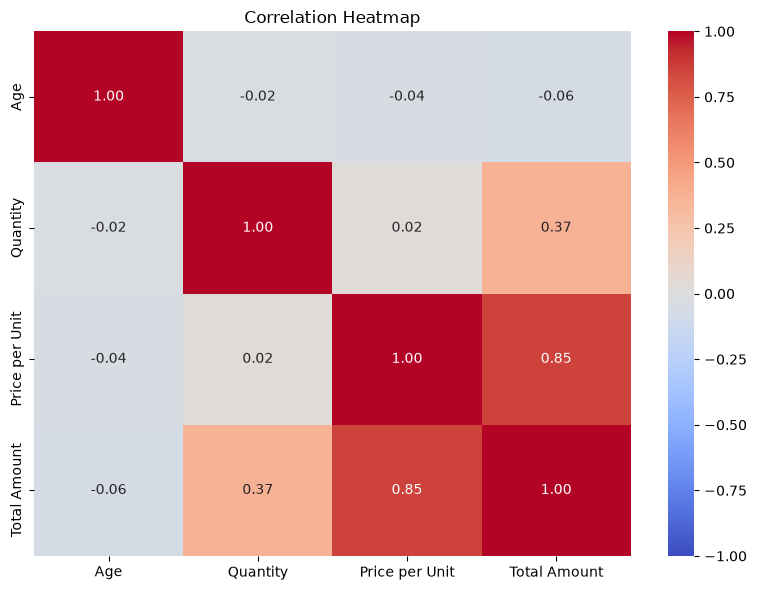

Correlation Matrix:


,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


In [16]:

numeric_columns = [
    "Age", "Quantity", "Price per Unit", "Total Amount"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlation Matrix:")
display(correlation)


In [17]:

print("Correlation with Total Amount:")
display(
    correlation["Total Amount"]
    .sort_values(ascending=False)
)


Correlation with Total Amount:


Total Amount      1.000000
Price per Unit    0.851925
Quantity          0.373707
Age              -0.060568
Name: Total Amount, dtype: float64